In [ ]:
import base64
import subprocess
from pathlib import Path
from kaggle_secrets import UserSecretsClient

secrets = UserSecretsClient()
token = secrets.get_secret("GITHUB_TOKEN")

username = "AnikMallick"
repo_name = "bn-proverbs-in-context"

repo_dir = Path("/kaggle/working") / repo_name

auth = base64.b64encode(
    f"{username}:{token}".encode()
).decode()

try:
    subprocess.run(
        [
            "git",
            "-c",
            f"http.https://github.com/.extraheader="
            f"AUTHORIZATION: basic {auth}",
            "clone",
            f"https://github.com/{username}/{repo_name}.git",
            str(repo_dir),
        ],
        check=True,
    )
finally:
    del token
    del auth

print("Repository cloned successfully.")

In [ ]:
%cd /kaggle/working/bn-proverbs-in-context

!pip install -e .

In [2]:
from pathlib import Path
from probad.utils import print_div
from probad.schema import TestItem, validate_items
import json
from typing import Any
import probad.builder as exp

DATA_PATH = Path("/kaggle/input/datasets/amallick0507/probad")

train_data = list(TestItem.load_items(DATA_PATH/"train.jsonl"))
test_data = list(TestItem.load_items(DATA_PATH/"test.jsonl"))
val_data = list(TestItem.load_items(DATA_PATH/"val.jsonl"))


source = DATA_PATH / "stopwords-bn.json"

try:
    data: Any = json.loads(source.read_text(encoding="utf-8-sig"))
except FileNotFoundError as exc:
    raise FileNotFoundError(f"Stopword file not found: {source}") from exc
except json.JSONDecodeError as exc:
    raise ValueError(
        f"Invalid JSON in stopword file {source}: "
        f"line {exc.lineno}, column {exc.colno}: {exc.msg}"
    ) from exc

BN_STOPWORDS =  frozenset([word.strip() for word in data])

print_div("train")
for issue in validate_items(train_data, BN_STOPWORDS):
    print(issue)

print_div("test")
for issue in validate_items(test_data, BN_STOPWORDS):
    print(issue)

print_div("val")
for issue in validate_items(val_data, BN_STOPWORDS):
    print(issue)

=============================================> train <==============================================
==============================================> test <==============================================
[WARNING] prv_088_1: en.correct_echoes_gloss: correct option reuses many literal-gloss words
[WARNING] prv_088_2: en.correct_echoes_gloss: correct option reuses many literal-gloss words
==============================================> val <===============================================


In [4]:
from kaggle_secrets import UserSecretsClient
import os
from probad.scoring import LoadBalancedModel

user_secrets = UserSecretsClient()
secret_value_1 = user_secrets.get_secret("HF_TOKEN")
os.environ['HF_TOKEN'] = secret_value_1

MODEL_NAME = "allenai/OLMo-2-0425-1B"
model = LoadBalancedModel(
    MODEL_NAME,
    gpu_ids=(0, 1)
)

tok = model.tok

config.json:   0%|          | 0.00/623 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.34k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.14M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/14.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

In [6]:
import pandas as pd


## E1 Experiment
Knowing: can the model finish the proverb when the last word is removed?

In [7]:
from probad.scoring import answer_one, generate, check_memorisation, check_memorisation_graded
from probad.builder import MEM_TEMPLATES


In [8]:
unique_test_data = {}
for t in test_data:
    if t.proverb.proverb_id not in unique_test_data:
        unique_test_data[t.proverb.proverb_id] = t

In [9]:
from itertools import product
from concurrent.futures import ThreadPoolExecutor, as_completed


def process_item(it, render, template):
    pid = it.proverb.proverb_id
    built = exp.e1_memorisation(it.model_dump(), render, template)

    if built is None:
        return None

    prompt, target = built
    output = generate(model, tok, prompt, 4)

    return {
        "model": MODEL_NAME,
        "proverb_id": pid,
        "render": render,
        "template": template,
        "prompt": prompt,
        "target": target,
        "output": output,
        "correct": check_memorisation(output, target),
        "correct_score": check_memorisation_graded(output, target),
        "label": "e1_memorisation",
        "variant": f"e1_memorisation(it, {render}, {template})",
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in unique_test_data.values():
        for render, template in product(["bengali", "english"], [0, 1, 2, 3, 4]):
            e1_futures.append(executor.submit(process_item, item, render, template))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [10]:
e1_results_df = pd.DataFrame(results)
e1_results_df.head(2)

,model,proverb_id,render,template,prompt,target,output,correct,correct_score,label,variant
0,allenai/OLMo-2-0425-1B,prv_001,bengali,1,এই প্রবাদটি সম্পূর্ণ করো: অতি লোভে তাঁতি,নষ্ট,কর�,False,0.0,e1_memorisation,"e1_memorisation(it, bengali, 1)"
1,allenai/OLMo-2-0425-1B,prv_001,bengali,0,প্রবাদ: অতি লোভে তাঁতি,নষ্ট,করে,False,0.0,e1_memorisation,"e1_memorisation(it, bengali, 0)"


In [11]:
e1_results_df.shape

(2000, 11)

In [12]:
sum(e1_results_df["correct"])

24

In [13]:
e1_results_df["correct_score"].mean()

np.float64(0.22075348883142998)

## E2 Experiment
Using: pick the right meaning in a conversation MAPS style

In [14]:
def item_info(it):
    return {"item_id": it["item_id"], "proverb_id": it["proverb"]["proverb_id"],
            "figurative": it["proverb"]["figurative"], "split": it["meta"]["split"],
            "subsets": it["meta"].get("subsets", [])}

In [15]:
def process_item(item):
    r = exp.e2_reasoning(item.model_dump())
    for s in range(1, 100):
        _r = exp.e2_reasoning(item.model_dump(), seed= s)
        if r[1] != _r[1]:
            break
    r = _r
    return {
        "model": MODEL_NAME,
        "label": "e2_reasoning",
        "variant": "exp.e2_reasoning(item.model_dump())",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }


results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(process_item, item)
        for item in test_data
    ]

    for future in as_completed(futures):
        results.append(future.result())

In [16]:
e2_results_df = pd.DataFrame(results)
e2_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e2_reasoning,exp.e2_reasoning(item.model_dump()),prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.824462,0.175538,-1.546875,0.904718
1,allenai/OLMo-2-0425-1B,e2_reasoning,exp.e2_reasoning(item.model_dump()),prv_001_2,prv_001,True,test,[maps_overlap],b,a,False,0.809878,0.190122,-1.449219,0.862557


In [17]:
sum(e2_results_df["correct"])

306

## E2 Literals

In [18]:
def process_item(item):
    r = exp.e2_reasoning(item.model_dump(), keys=("correct", "literal"))
    for s in range(1, 100):
        _r = exp.e2_reasoning(item.model_dump(), keys=("correct", "literal"), seed= s)
        if r[1] != _r[1]:
            break
    r = _r
    return {
        "model": MODEL_NAME,
        "label": "e2_reasoning",
        "variant": "exp.e2_reasoning(item.model_dump())",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }


results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(process_item, item)
        for item in test_data
    ]

    for future in as_completed(futures):
        results.append(future.result())

In [19]:
e2_lit_results_df = pd.DataFrame(results)
e2_lit_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e2_reasoning,exp.e2_reasoning(item.model_dump()),prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.768386,0.231614,-1.199219,0.921585
1,allenai/OLMo-2-0425-1B,e2_reasoning,exp.e2_reasoning(item.model_dump()),prv_001_2,prv_001,True,test,[maps_overlap],b,a,False,0.774583,0.225417,-1.234375,0.912389


In [20]:
sum(e2_lit_results_df["correct"])

306

## E3 and E4
Knowing vs using: E2 accuracy for memorised vs not-memorised proverbs

In [21]:
def e3_knowing_vs_using(e1_df, e2_df, render="bengali"):
    """E3: is accuracy higher on proverbs the model has memorised?
    memorised = any template completes the proverb (MAPS rule)."""
    mem = (e1_df[e1_df["render"] == render]
           .groupby("proverb_id")["correct"].any().rename("memorised"))
    item = e2_df.groupby(["item_id", "proverb_id"])["correct"].mean().reset_index()  # collapses option orders
    df = item.merge(mem, on="proverb_id", how="left").fillna({"memorised": False})
    df["memorised"] = df["memorised"].astype(bool)
    df["used"] = df["correct"] >= 0.5
    df["quadrant"] = df["memorised"].map({True: "know", False: "dont_know"}) + "+" + \
                     df["used"].map({True: "use", False: "dont_use"})
    acc = df.groupby("memorised")["correct"].agg(acc="mean", n="size")
    quad = df["quadrant"].value_counts()
    return acc, quad, df


def e4_figurative(e2_df):
    """E4: accuracy on figurative vs non-figurative proverbs."""
    item = e2_df.groupby(["item_id", "figurative"])["correct"].mean().reset_index()
    return item.groupby("figurative")["correct"].agg(acc="mean", n="size")

In [22]:
acc, quad, e3_df = e3_knowing_vs_using(e1_results_df, e2_results_df, render="bengali")
acc_lit, quad_lit, _ = e3_knowing_vs_using(e1_results_df, e2_lit_results_df, render="bengali")
display(acc); print(quad)
display(acc_lit); print(quad_lit)

display(e4_figurative(e2_results_df))
display(e4_figurative(e2_lit_results_df))

,acc,n
memorised,,
False,0.514530,585
True,0.333333,15


quadrant
dont_know+use         301
dont_know+dont_use    284
know+dont_use          10
know+use                5
Name: count, dtype: int64


,acc,n
memorised,,
False,0.514530,585
True,0.333333,15


quadrant
dont_know+use         301
dont_know+dont_use    284
know+dont_use          10
know+use                5
Name: count, dtype: int64


,acc,n
figurative,,
False,0.600000,90
True,0.494118,510


,acc,n
figurative,,
False,0.600000,90
True,0.494118,510


In [23]:
acc, quad, e3_df = e3_knowing_vs_using(e1_results_df, e2_results_df, render="english")
acc_lit, quad_lit, _ = e3_knowing_vs_using(e1_results_df, e2_lit_results_df, render="english")
display(acc); print(quad)
display(acc_lit); print(quad_lit)

display(e4_figurative(e2_results_df))
display(e4_figurative(e2_lit_results_df))

,acc,n
memorised,,
False,0.516239,585
True,0.266667,15


quadrant
dont_know+use         302
dont_know+dont_use    283
know+dont_use          11
know+use                4
Name: count, dtype: int64


,acc,n
memorised,,
False,0.516239,585
True,0.266667,15


quadrant
dont_know+use         302
dont_know+dont_use    283
know+dont_use          11
know+use                4
Name: count, dtype: int64


,acc,n
figurative,,
False,0.600000,90
True,0.494118,510


,acc,n
figurative,,
False,0.600000,90
True,0.494118,510


## E5 - control

In [25]:
def process_item(item):
    r = exp.e5_control(item.model_dump())
    for s in range(1, 100):
        _r = exp.e5_control(item.model_dump(), seed= s)
        if r[1] != _r[1]:
            break
    r = _r
    return {
        "model": MODEL_NAME,
        "label": "e5_control",
        "variant": "exp.e5_control(item.model_dump())",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }


results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(process_item, item)
        for item in test_data
    ]

    for future in as_completed(futures):
        results.append(future.result())

In [26]:
e5_control_results_df = pd.DataFrame(results)
e5_control_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e5_control,exp.e5_control(item.model_dump()),prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.899475,0.100525,-2.191406,0.860509
1,allenai/OLMo-2-0425-1B,e5_control,exp.e5_control(item.model_dump()),prv_001_2,prv_001,True,test,[maps_overlap],b,a,False,0.886027,0.113973,-2.050781,0.802562


In [27]:
sum(e5_control_results_df["correct"])

306

## E5 - negation

In [28]:
def process_item(item, question):
    r = exp.e5_negated(item.model_dump(), question=question) #"neg", "neg1", "neg2", "neg3", "neg4"
    for s in range(1, 100):
        _r = exp.e5_negated(item.model_dump(), question=question, seed= s)
        if r[1] != _r[1]:
            break
    r = _r
    return {
        "model": MODEL_NAME,
        "label": "e5_negated",
        "variant": f"exp.e5_negated(item.model_dump(), {question})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["neg", "neg1", "neg2", "neg3", "neg4"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [29]:
e5_negated_results_df = pd.DataFrame(results)
e5_negated_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e5_negated,"exp.e5_negated(item.model_dump(), neg)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.814053,0.185947,1.476563,0.910296
1,allenai/OLMo-2-0425-1B,e5_negated,"exp.e5_negated(item.model_dump(), neg1)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.750553,0.249447,1.101562,0.945888


In [30]:
sum(e5_negated_results_df["correct"])

1470

## E6

In [31]:
def process_item(item, condition):
    r = exp.e6_translation(item.model_dump(), condition=condition)
    for s in range(1, 100):
        _r = exp.e6_translation(item.model_dump(), condition=condition, seed= s)
        if r[1] != _r[1]:
            break
    r = _r
    return {
        "model": MODEL_NAME,
        "label": "e6_translation",
        "variant": f"exp.e6_translation(item.model_dump(), {condition})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["bn_native", "en_romanised", "en_gloss"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [32]:
e6_results_df = pd.DataFrame(results)
e6_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e6_translation,"exp.e6_translation(item.model_dump(), en_roman...",prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.833325,0.166675,-1.609375,0.960177
1,allenai/OLMo-2-0425-1B,e6_translation,"exp.e6_translation(item.model_dump(), bn_native)",prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.824462,0.175538,-1.546875,0.904718


In [33]:
sum(e6_results_df["correct"])

932

## E7

In [34]:
fewshot = [v.model_dump() for v in val_data]
def process_item(item):
    k = 3
    r = exp.e7_few_shot(item.model_dump(), demo_items=fewshot, k=k)
    for s in range(1, 100):
        _r = exp.e7_few_shot(item.model_dump(), demo_items=fewshot, k=k,seed= s)
        if r[1] != _r[1]:
            break
    r = _r
    return {
        "model": MODEL_NAME,
        "label": "e7_few_shot",
        "variant": f"exp.e7_few_shot(item.model_dump(), fewshot, {k})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(process_item, item)
        for item in test_data
    ]

    for future in as_completed(futures):
        results.append(future.result())

In [35]:
e7_results_df = pd.DataFrame(results)
e7_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e7_few_shot,"exp.e7_few_shot(item.model_dump(), fewshot, 3)",prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.632276,0.367724,-0.541992,0.986000
1,allenai/OLMo-2-0425-1B,e7_few_shot,"exp.e7_few_shot(item.model_dump(), fewshot, 3)",prv_001_2,prv_001,True,test,[maps_overlap],b,a,False,0.732879,0.267121,-1.009277,0.990068


In [36]:
sum(e7_results_df["correct"])

304

## E9

In [37]:
def process_item(item, template):
    r = exp.e9_template(item.model_dump(), template=template)
    for s in range(1, 100):
        _r = exp.e9_template(item.model_dump(), template=template,seed= s)
        if r[1] != _r[1]:
            break
    r = _r
    return {
        "model": MODEL_NAME,
        "label": "e9_template",
        "variant": f"exp.e9_template(item.model_dump(), {template})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }




results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in [1, 2, 3]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [38]:
e9_results_df = pd.DataFrame(results)
e9_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e9_template,"exp.e9_template(item.model_dump(), 1)",prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.895443,0.104557,-2.147583,0.005933
1,allenai/OLMo-2-0425-1B,e9_template,"exp.e9_template(item.model_dump(), 2)",prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.783160,0.216840,-1.284180,0.982771


In [39]:
sum(e9_results_df["correct"])

918

In [41]:
OUT = Path("/kaggle/working/results_maps_alligned_swaped")
os.mkdir(OUT)

In [42]:
e1_results_df.to_csv(OUT / "e1_results_df_swaped.csv", index=False)
e2_results_df.to_csv(OUT / "e2_results_df_swaped.csv", index=False)
e2_lit_results_df.to_csv(OUT / "e2_lit_results_df_swaped.csv", index=False)
e5_control_results_df.to_csv(OUT / "e5_control_results_df_swaped.csv", index=False)
e5_negated_results_df.to_csv(OUT / "e5_negated_results_df_swaped.csv", index=False)
e6_results_df.to_csv(OUT / "e6_results_df_swaped.csv", index=False)
e7_results_df.to_csv(OUT / "e7_results_df_swaped.csv", index=False)
e9_results_df.to_csv(OUT / "e9_results_df_swaped.csv", index=False)

In [43]:
acc, quad, e3_df = e3_knowing_vs_using(e1_results_df, e2_results_df, render="bengali")
acc_lit, quad_lit, _ = e3_knowing_vs_using(e1_results_df, e2_lit_results_df, render="bengali")
display(acc); display(quad)
display(acc_lit); display(quad_lit)

display(e4_figurative(e2_results_df))
display(e4_figurative(e2_lit_results_df))

,acc,n
memorised,,
False,0.514530,585
True,0.333333,15


quadrant
dont_know+use         301
dont_know+dont_use    284
know+dont_use          10
know+use                5
Name: count, dtype: int64

,acc,n
memorised,,
False,0.514530,585
True,0.333333,15


quadrant
dont_know+use         301
dont_know+dont_use    284
know+dont_use          10
know+use                5
Name: count, dtype: int64

,acc,n
figurative,,
False,0.600000,90
True,0.494118,510


,acc,n
figurative,,
False,0.600000,90
True,0.494118,510


In [44]:
acc.to_csv(OUT / "e3_acc_bengali_df_swaped.csv", index=False)
quad.to_csv(OUT / "e3_quad_bengali_df_swaped.csv", index=False)
e3_df.to_csv(OUT / "e3_results_bengali_df_swaped.csv", index=False)

acc_lit.to_csv(OUT / "e3_acc_bengali_lit_df_swaped.csv", index=False)
quad_lit.to_csv(OUT / "e3_quad_bengali_lit_df_swaped.csv", index=False)

e4_figurative(e2_results_df).to_csv(OUT / "e4_figurative_bengali_df_swaped.csv", index=False)
e4_figurative(e2_lit_results_df).to_csv(OUT / "e4_figurative_bengali_lit_df_swaped.csv", index=False)

In [45]:
acc, quad, e3_df = e3_knowing_vs_using(e1_results_df, e2_results_df, render="english")
acc_lit, quad_lit, _ = e3_knowing_vs_using(e1_results_df, e2_lit_results_df, render="english")
display(acc); display(quad)
display(acc_lit); display(quad_lit)

display(e4_figurative(e2_results_df))
display(e4_figurative(e2_lit_results_df))

,acc,n
memorised,,
False,0.516239,585
True,0.266667,15


quadrant
dont_know+use         302
dont_know+dont_use    283
know+dont_use          11
know+use                4
Name: count, dtype: int64

,acc,n
memorised,,
False,0.516239,585
True,0.266667,15


quadrant
dont_know+use         302
dont_know+dont_use    283
know+dont_use          11
know+use                4
Name: count, dtype: int64

,acc,n
figurative,,
False,0.600000,90
True,0.494118,510


,acc,n
figurative,,
False,0.600000,90
True,0.494118,510


In [46]:
acc.to_csv(OUT / "e3_acc_english_df_swaped.csv", index=False)
quad.to_csv(OUT / "e3_quad_english_df_swaped.csv", index=False)
e3_df.to_csv(OUT / "e3_results_english_df_swaped.csv", index=False)

acc_lit.to_csv(OUT / "e3_acc_english_lit_df_swaped.csv", index=False)
quad_lit.to_csv(OUT / "e3_quad_english_lit_df_swaped.csv", index=False)

e4_figurative(e2_results_df).to_csv(
    OUT / "e4_figurative_english_df_swaped.csv", index=False
)
e4_figurative(e2_lit_results_df).to_csv(
    OUT / "e4_figurative_english_lit_df_swaped.csv", index=False
)

## Analysis

In [47]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

FIG = OUT / "figs"; FIG.mkdir(parents=True, exist_ok=True)

def item_level(df, by=("label",)):
    """Collapse option orders: one row per item (correct = share of orders right)."""
    df = df.copy()
    df["p_gold"] = df.apply(lambda r: r[f"p_{r['gold'].lower()}"], axis=1)
    df["n_opts"] = df.filter(regex=r"^p_[abc]$").notna().sum(axis=1)
    keys = [k for k in dict.fromkeys([*by, "item_id", "proverb_id", "figurative"]) if k in df]
    return df.groupby(keys, dropna=False).agg(
        correct=("correct", "mean"), p_gold=("p_gold", "mean"), margin=("margin", "mean"),
        letter_mass=("letter_mass", "mean"), n_opts=("n_opts", "first")).reset_index()

def ci(values, clusters, n=2000, seed=0):
    """95% CI of the mean, resampling whole proverbs."""
    _, inv = np.unique(np.asarray(clusters), return_inverse=True)
    s, c = np.bincount(inv, np.asarray(values, float)), np.bincount(inv)
    pick = np.random.default_rng(seed).integers(0, len(c), (n, len(c)))
    return np.percentile(s[pick].sum(1) / c[pick].sum(1), [2.5, 97.5])

def summary(df, name, by="label"):
    it = item_level(df, (by,))
    rows = []
    for key, g in it.groupby(by):
        lo, hi = ci(g["correct"], g["proverb_id"])
        raw = df[df[by] == key]
        rows.append({"exp": name, by: key, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi,
                     "chance": 1 / g["n_opts"].mean(), "n": len(g),
                     "p_gold": g["p_gold"].mean(), "letter_mass": g["letter_mass"].median(),
                     "pred_a": (raw["pred"].str.lower() == "a").mean(),            # position bias
                     "acc_gold_a": raw.loc[raw["gold"].str.lower() == "a", "correct"].mean(),
                     "acc_gold_b": raw.loc[raw["gold"].str.lower() == "b", "correct"].mean()})
    return pd.DataFrame(rows)

def paired(a, b, name_a, name_b):
    """b - a on shared items, CI over proverbs, McNemar counts."""
    m = item_level(a, ()).merge(item_level(b, ()), on=["item_id", "proverb_id"], suffixes=("_a", "_b"))
    d = m["correct_b"] - m["correct_a"]
    lo, hi = ci(d, m["proverb_id"])
    return {"a": name_a, "b": name_b, "acc_a": m["correct_a"].mean(), "acc_b": m["correct_b"].mean(),
            "diff": d.mean(), "ci_lo": lo, "ci_hi": hi, "a_only": int((d < 0).sum()),
            "b_only": int((d > 0).sum()), "n": len(m)}

def bar(tab, title, fname, x="label"):
    fig, ax = plt.subplots(figsize=(max(4, 0.9 * len(tab) + 2), 3.5))
    ax.bar(tab[x].astype(str), tab["acc"], yerr=[tab["acc"] - tab["ci_lo"], tab["ci_hi"] - tab["acc"]],
           capsize=4, color="#4C72B0")
    for i, c in enumerate(tab["chance"]):
        ax.hlines(c, i - 0.4, i + 0.4, colors="red", linestyles="--")
    ax.set_ylim(0, 1); ax.set_ylabel("accuracy"); ax.set_title(title)
    plt.xticks(rotation=30, ha="right"); plt.tight_layout(); fig.savefig(FIG / fname, dpi=150); plt.show()

,exp,label,acc,ci_lo,ci_hi,chance,n,p_gold,letter_mass,pred_a,acc_gold_a,acc_gold_b,cond
0,E2,e2_reasoning,0.510,0.470,0.552,0.5,600,0.503,0.900,1.000,1.000,0.000,E2:e2_reasoning
1,E2_lit,e2_reasoning,0.510,0.470,0.552,0.5,600,0.509,0.895,1.000,1.000,0.000,E2_lit:e2_reasoning
2,E5_neg,e5_negated,0.490,0.448,0.530,0.5,600,0.499,0.933,1.000,1.000,0.000,E5_neg:e5_negated
3,E5_control,e5_control,0.510,0.470,0.552,0.5,600,0.506,0.929,1.000,1.000,0.000,E5_control:e5_control
4,E6,e6_translation,0.518,0.478,0.558,0.5,600,0.522,0.931,0.990,0.998,0.018,E6:e6_translation
5,E7,e7_few_shot,0.507,0.467,0.548,0.5,600,0.497,0.985,0.997,0.993,0.000,E7:e7_few_shot
6,E9,e9_template,0.510,0.470,0.552,0.5,600,0.504,0.632,1.000,1.000,0.000,E9:e9_template


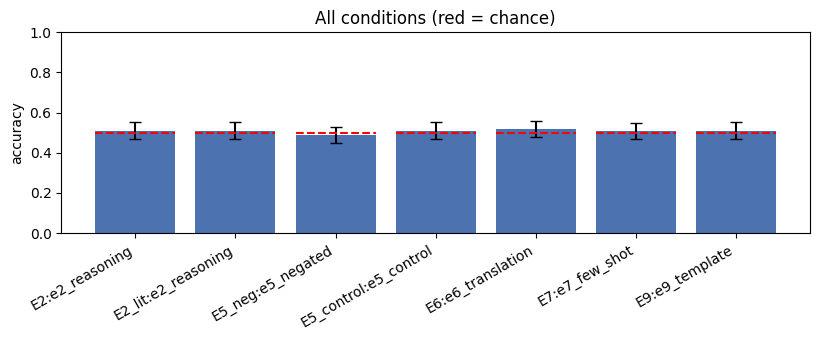

In [48]:
# all MCQ conditions in one table
runs = {"E2": e2_results_df, "E2_lit": e2_lit_results_df, "E5_neg": e5_negated_results_df,
        "E5_control": e5_control_results_df, "E6": e6_results_df, "E7": e7_results_df, "E9": e9_results_df}
overview = pd.concat([summary(df, name) for name, df in runs.items()], ignore_index=True)
overview["cond"] = overview["exp"] + ":" + overview["label"].astype(str)
overview.to_csv(OUT / "overview.csv", index=False)
display(overview.round(3))
bar(overview, "All conditions (red = chance)", "overview.png", x="cond")

E1 per template
 render    bengali  english
template                  
0           0.010    0.005
1           0.005    0.015
2           0.005    0.015
3           0.015    0.015
4           0.020    0.015
E1 memorised (any template)
           mean  size
render              
bengali  0.025   200
english  0.025   200


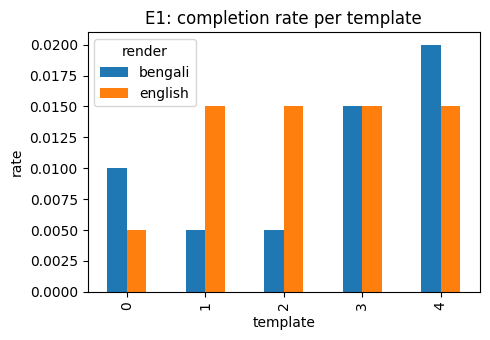

In [49]:
# E1 memorisation
mem_t = e1_results_df.groupby(["render", "template"])["correct"].mean().unstack("render")
mem_any = e1_results_df.groupby(["render", "proverb_id"])["correct"].any().groupby("render").agg(["mean", "size"])
print("E1 per template\n", mem_t.round(3)); print("E1 memorised (any template)\n", mem_any.round(3))
mem_t.plot.bar(figsize=(5, 3.5), title="E1: completion rate per template", ylabel="rate")
plt.tight_layout(); plt.savefig(FIG / "e1_templates.png", dpi=150); plt.show()

In [50]:
# E3 knowing vs using
def e3(e2_df, render):
    mem = e1_results_df[e1_results_df["render"] == render].groupby("proverb_id")["correct"].any().rename("memorised")
    it = item_level(e2_df, ()).merge(mem, on="proverb_id", how="left").fillna({"memorised": False})
    it["memorised"] = it["memorised"].astype(bool)
    it["used"] = it["correct"] >= 0.5
    rows = []
    for m, g in it.groupby("memorised"):
        lo, hi = ci(g["correct"], g["proverb_id"])
        rows.append({"render": render, "memorised": m, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi, "n": len(g)})
    quad = pd.crosstab(it["memorised"].map({True: "knows", False: "doesn't know"}),
                       it["used"].map({True: "uses", False: "doesn't use"}))
    return pd.DataFrame(rows), quad, it

E2 bengali 
 used          doesn't use  uses
memorised                      
doesn't know          284   301
knows                  10     5
E2 english 
 used          doesn't use  uses
memorised                      
doesn't know          283   302
knows                  11     4
E2_lit bengali 
 used          doesn't use  uses
memorised                      
doesn't know          284   301
knows                  10     5
E2_lit english 
 used          doesn't use  uses
memorised                      
doesn't know          283   302
knows                  11     4


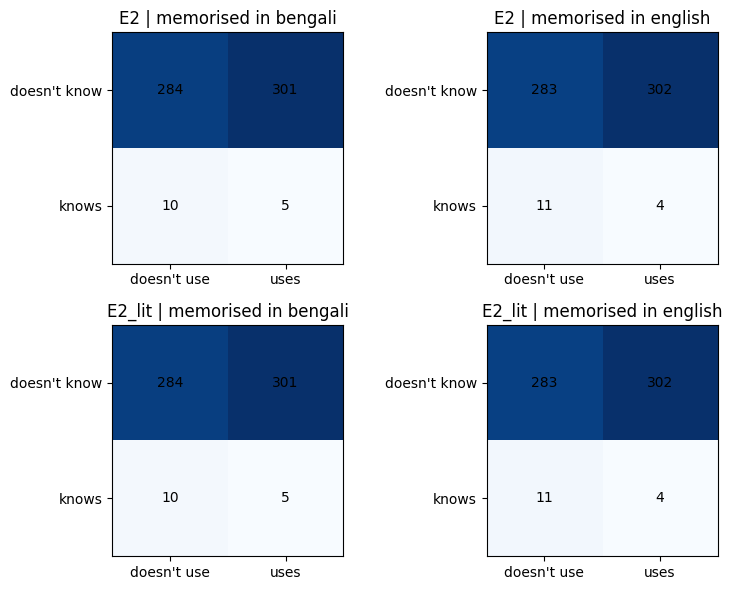

    render  memorised    acc  ci_lo  ci_hi    n     exp
0  bengali      False  0.515  0.474  0.554  585      E2
1  bengali       True  0.333  0.333  0.333   15      E2
2  english      False  0.516  0.477  0.559  585      E2
3  english       True  0.267  0.133  0.333   15      E2
4  bengali      False  0.515  0.474  0.554  585  E2_lit
5  bengali       True  0.333  0.333  0.333   15  E2_lit
6  english      False  0.516  0.477  0.559  585  E2_lit
7  english       True  0.267  0.133  0.333   15  E2_lit


In [51]:
e3_tabs, fig, axes = [], *plt.subplots(2, 2, figsize=(8, 6))
for i, (name, df) in enumerate({"E2": e2_results_df, "E2_lit": e2_lit_results_df}.items()):
    for j, render in enumerate(e1_results_df["render"].unique()[:2]):
        acc_, quad_, _ = e3(df, render)
        e3_tabs.append(acc_.assign(exp=name)); print(name, render, "\n", quad_)
        ax = axes[i, j]; ax.imshow(quad_.values, cmap="Blues")
        for (r, c), v in np.ndenumerate(quad_.values):
            ax.text(c, r, v, ha="center", va="center")
        ax.set_xticks(range(quad_.shape[1]), quad_.columns); ax.set_yticks(range(quad_.shape[0]), quad_.index)
        ax.set_title(f"{name} | memorised in {render}")
plt.tight_layout(); fig.savefig(FIG / "e3_quadrants.png", dpi=150); plt.show()
e3_tab = pd.concat(e3_tabs, ignore_index=True); e3_tab.to_csv(OUT / "e3_knowing_vs_using.csv", index=False)
print(e3_tab.round(3).to_string())

      exp  figurative    acc  ci_lo  ci_hi  chance    n  p_gold  letter_mass  pred_a  acc_gold_a  acc_gold_b
0      E2       False  0.600  0.489  0.700     0.5   90   0.559        0.890     1.0         1.0         0.0
1      E2        True  0.494  0.453  0.537     0.5  510   0.493        0.902     1.0         1.0         0.0
2  E2_lit       False  0.600  0.489  0.700     0.5   90   0.567        0.889     1.0         1.0         0.0
3  E2_lit        True  0.494  0.453  0.537     0.5  510   0.499        0.896     1.0         1.0         0.0


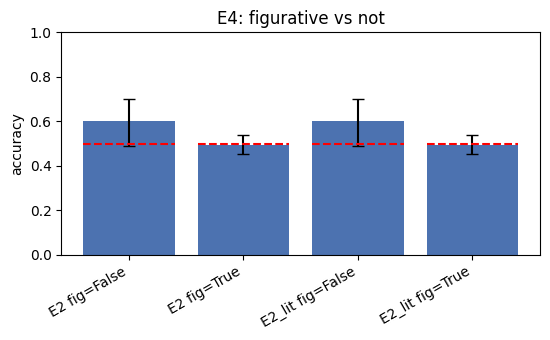

In [52]:
# E4 figurative
e4_tab = pd.concat([summary(df, name, by="figurative") for name, df in
                    {"E2": e2_results_df, "E2_lit": e2_lit_results_df}.items()], ignore_index=True)
e4_tab.to_csv(OUT / "e4_figurative.csv", index=False); print(e4_tab.round(3).to_string())
bar(e4_tab.assign(cond=e4_tab["exp"] + " fig=" + e4_tab["figurative"].astype(str)), "E4: figurative vs not", "e4.png", x="cond")

In [53]:
# E5 does the model read the question?
neg = item_level(e5_negated_results_df)
pos = item_level(e2_results_df, ())[["item_id", "correct"]].rename(columns={"correct": "pos"})
e5_tab = []
for q, g in neg.groupby("label"):
    m = g.merge(pos, on="item_id")
    # 2 options: in the negated prompt, "not correct" means the model picked the correct meaning
    m["same_choice"] = (m["pos"] >= 0.5) == (m["correct"] < 0.5)
    e5_tab.append({"question": q, "acc_pos": m["pos"].mean(), "acc_neg": m["correct"].mean(),
                   "sum": m["pos"].mean() + m["correct"].mean(),   # ~1.0 = ignores the question
                   "same_option_both": m["same_choice"].mean(), "n": len(m)})
e5_tab = pd.DataFrame(e5_tab); e5_tab.to_csv(OUT / "e5_negation.csv", index=False); display(e5_tab.round(3))
print("no-question control vs E2:", paired(e5_control_results_df, e2_results_df, "control", "E2"))

,question,acc_pos,acc_neg,sum,same_option_both,n
0,e5_negated,0.51,0.49,1.0,1.0,600


no-question control vs E2: {'a': 'control', 'b': 'E2', 'acc_a': np.float64(0.51), 'acc_b': np.float64(0.51), 'diff': np.float64(0.0), 'ci_lo': np.float64(0.0), 'ci_hi': np.float64(0.0), 'a_only': 0, 'b_only': 0, 'n': 600}


,exp,a,b,acc_a,acc_b,diff,ci_lo,ci_hi,a_only,b_only,n
0,E6,E2,e6_translation,0.51,0.518,0.008,0.003,0.013,2,15,600
1,E7,E2,e7_few_shot,0.51,0.507,-0.003,-0.008,0.000,2,0,600
2,E9,E2,e9_template,0.51,0.510,0.000,0.000,0.000,0,0,600


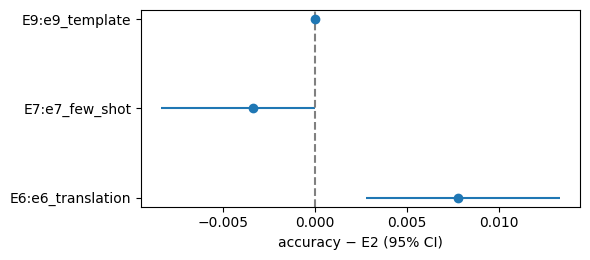

In [54]:
# E6 / E7 / E9 vs E2 (paired)
diffs = []
for name, df in {"E6": e6_results_df, "E7": e7_results_df, "E9": e9_results_df}.items():
    for lab, g in df.groupby("label"):
        diffs.append({"exp": name, **paired(e2_results_df, g, "E2", lab)})
diffs = pd.DataFrame(diffs); diffs.to_csv(OUT / "paired_vs_e2.csv", index=False); display(diffs.round(3))
fig, ax = plt.subplots(figsize=(6, 0.4 * len(diffs) + 1.5))
ax.errorbar(diffs["diff"], range(len(diffs)), xerr=[diffs["diff"] - diffs["ci_lo"], diffs["ci_hi"] - diffs["diff"]], fmt="o")
ax.axvline(0, color="grey", ls="--"); ax.set_yticks(range(len(diffs)), diffs["exp"] + ":" + diffs["b"].astype(str))
ax.set_xlabel("accuracy − E2 (95% CI)"); plt.tight_layout(); fig.savefig(FIG / "paired_vs_e2.png", dpi=150); plt.show()

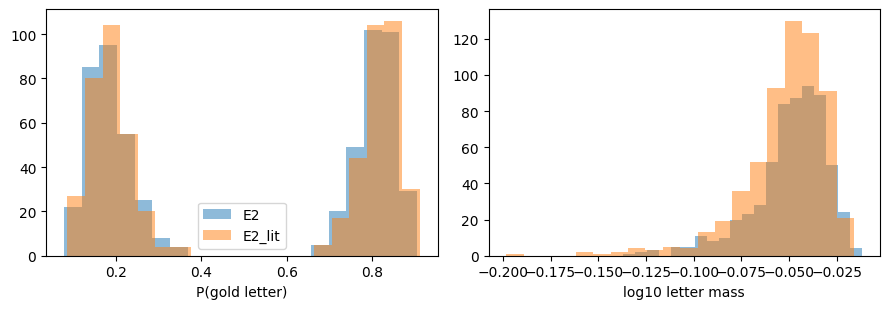

       item_id proverb_id  figurative  correct    p_gold    margin  letter_mass  n_opts  correct_lit
130  prv_060_2    prv_060        True      0.0  0.077797 -2.472656     0.932963       2          0.0
286  prv_126_2    prv_126        True      0.0  0.087720 -2.341797     0.950599       2          0.0
275  prv_121_3    prv_121        True      0.0  0.092688 -2.281250     0.875783       2          0.0
19   prv_007_2    prv_007        True      0.0  0.096706 -2.234375     0.941060       2          0.0
557  prv_242_3    prv_242       False      0.0  0.098425 -2.214844     0.873988       2          0.0
257  prv_114_3    prv_114        True      0.0  0.100879 -2.187500     0.945902       2          0.0
50   prv_020_3    prv_020        True      0.0  0.101589 -2.179688     0.923649       2          0.0
532  prv_225_2    prv_225       False      0.0  0.101947 -2.175781     0.937919       2          0.0
266  prv_118_3    prv_118        True      0.0  0.106505 -2.126953     0.946504       2    

In [55]:
# confidence / letter mass
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for name, df in {"E2": e2_results_df, "E2_lit": e2_lit_results_df}.items():
    it = item_level(df, ())
    axes[0].hist(it["p_gold"], bins=20, alpha=0.5, label=name)
    axes[1].hist(np.log10(it["letter_mass"]), bins=20, alpha=0.5, label=name)
axes[0].set_xlabel("P(gold letter)"); axes[1].set_xlabel("log10 letter mass")
axes[0].legend(); plt.tight_layout(); fig.savefig(FIG / "confidence.png", dpi=150); plt.show()

# hardest items (for error analysis)
hard = item_level(e2_results_df, ()).merge(item_level(e2_lit_results_df, ())[["item_id", "correct"]],
                                           on="item_id", suffixes=("", "_lit"))
hard = hard.sort_values(["correct", "correct_lit", "p_gold"]).head(30)
hard.to_csv(OUT / "hardest_items.csv", index=False); print(hard.head(10).to_string())

In [56]:
!zip -r /kaggle/working/probad_maps_E1_to_E7andE9_kaggle_results_swaped.zip /kaggle/working/results_maps_alligned_swaped

  adding: kaggle/working/results_maps_alligned_swaped/ (stored 0%)
  adding: kaggle/working/results_maps_alligned_swaped/e1_results_df_swaped.csv (deflated 92%)
  adding: kaggle/working/results_maps_alligned_swaped/e2_results_df_swaped.csv (deflated 79%)
  adding: kaggle/working/results_maps_alligned_swaped/e4_figurative.csv (deflated 55%)
  adding: kaggle/working/results_maps_alligned_swaped/e3_results_bengali_df_swaped.csv (deflated 91%)
  adding: kaggle/working/results_maps_alligned_swaped/figs/ (stored 0%)
  adding: kaggle/working/results_maps_alligned_swaped/figs/paired_vs_e2.png (deflated 16%)
  adding: kaggle/working/results_maps_alligned_swaped/figs/e1_templates.png (deflated 21%)
  adding: kaggle/working/results_maps_alligned_swaped/figs/confidence.png (deflated 21%)
  adding: kaggle/working/results_maps_alligned_swaped/figs/e3_quadrants.png (deflated 20%)
  adding: kaggle/working/results_maps_alligned_swaped/figs/e4.png (deflated 16%)
  adding: kaggle/working/results_maps_all

In [60]:
r = exp.e2_reasoning(train_data[0].model_dump())
generate(model, tok, r[0], max_new_tokens=50)

' a'

In [61]:
r

("question: what does the person mean by the proverb?\nproverb:'ইটটি মারলে পাটকেলটি খেতে হয়'\ncontext: রাজেশ: সুমন সপ্তাহের পর সপ্তাহ অনলাইনে প্রাক্তন সহকর্মীকে ট্রোল করেছিল, আর এখন সে সুমনের পুরোনো লজ্জার সব মেসেজ পোস্ট করে দিয়েছে। ইপ্সিতা: ইটটি মারলে পাটকেলটি খেতে হয়।\nchoices: a: ইপ্সিতার ধারণা ঝগড়াটা আসলে প্রাক্তন সহকর্মীই প্রথমে শুরু করেছিল। b: সুমন আগে আঘাত করেছিল, তাই পাল্টা আঘাত আসাটাই স্বাভাবিক ছিল।\nanswer:",
 'b',
 ['a', 'b'])

In [63]:
enc = tok(r[0], return_tensors="pt").to(model.device)
out = model.generate(**enc, max_new_tokens=100, do_sample=False,
                     pad_token_id=tok.pad_token_id or tok.eos_token_id)
tok.decode(out[0, enc.input_ids.shape[1]:], skip_special_tokens=True)

' a'